# GPU Training Notebook

This notebook allows us to train our model using a GPU.

**Note:** Since the *HubroHub* environment is shared with other students, please remember to stop all GPU processes when your training is complete.

## Install Python Libraries

Start by running the following cell to install required libraries:

In [ ]:
!pip install datasets tokenizers

## Imports

Run the following cell to import the necessary files and review the configuration.

In [2]:
from pathlib import Path
from tokenizer import train_tokenizer
from train import train_model
from config import config
from utils import print_config

print_config(config)

Using configuration:
	seed: 0
	dataset: gooaq_subset
	split: train
	device: cuda
	vocab_size: 20000
	min_frequency: 5
	unk_token: [UNK]
	sep_token: [SEP]
	end_token: [END]
	pad_token: [PAD]
	tokenizer_filename: temp/tokenizer.json
	embed_size: 512
	num_heads: 8
	num_layers: 5
	dropout_p: 0.1
	max_len: 128
	model_train_fraction: 1.0
	batch_size: 128
	dataloader_num_workers: 2
	lr: 0.0001
	num_epochs: 5
	model_filename: temp/model.pth
	optimizer_filename: temp/optimizer.pth
****************************************************************************************************


## Training the Tokenizer

Train and save the tokenizer. This might take a few minutes to complete. But you only have to do this once as it will save the tokenizer for later use.

In [3]:
from pathlib import Path

if not Path(config.tokenizer_filename).exists():
  tokenizer = train_tokenizer(config)
else:
  print(f"Tokenizer already exists at {config.tokenizer_filename}")

Combining strings...


100%|██████████| 859765/859765 [00:16<00:00, 52460.35it/s]





Saved tokenizer to temp/tokenizer.json


## Training Your Model

We use the `train_model` function from `train.py`. This will save a model (and optimizer) checkpoint after every 500 batches.

When you have trained your model for around 3-5 epochs, download the model and tokenizer files to keep a copy in your local `temp` folder. You can now use these when doing inference (text generation).

Note that a single epoch might take around 15-30 minutes to complete.

In [4]:
train_model(config)

Using configuration:
	seed: 0
	dataset: gooaq_subset
	split: train
	device: cuda
	vocab_size: 20000
	min_frequency: 5
	unk_token: [UNK]
	sep_token: [SEP]
	end_token: [END]
	pad_token: [PAD]
	tokenizer_filename: temp/tokenizer.json
	embed_size: 512
	num_heads: 8
	num_layers: 5
	dropout_p: 0.1
	max_len: 128
	model_train_fraction: 1.0
	batch_size: 128
	dataloader_num_workers: 2
	lr: 0.0001
	num_epochs: 5
	model_filename: temp/model.pth
	optimizer_filename: temp/optimizer.pth
****************************************************************************************************
Number of parameters in the model: 36,261,920
Loaded dataset of size 859765 with columns ['question', 'answer']


[01 | 05] Loss: 4.0505: 100%|██████████| 6717/6717 [10:31<00:00, 10.64it/s]


Mean Epoch Cross-Entropy Loss: 4.6980



[02 | 05] Loss: 3.6761: 100%|██████████| 6717/6717 [10:19<00:00, 10.84it/s]


Mean Epoch Cross-Entropy Loss: 3.7925


...


[04 | 05] Loss: 3.1184: 100%|██████████| 6717/6717 [10:17<00:00, 10.88it/s]


Mean Epoch Cross-Entropy Loss: 3.2555



[05 | 05] Loss: 3.2185: 100%|██████████| 6717/6717 [10:18<00:00, 10.86it/s]



Mean Epoch Cross-Entropy Loss: 3.1230


OptimizedModule(
  (_orig_mod): TransformerModel(
    (embedding): Embedding(20000, 512)
    (dropout): Dropout(p=0.1, inplace=False)
    (pos_encoder): PositionalEncoding()
    (layers): ModuleList(
      (0-4): 5 x DecoderBlock(
        (norm1): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
        (attention): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=512, out_features=512, bias=True)
        )
        (dropout): Dropout(p=0.1, inplace=False)
        (mlp): Sequential(
          (0): Linear(in_features=512, out_features=2048, bias=True)
          (1): GELU(approximate='none')
          (2): Linear(in_features=2048, out_features=512, bias=True)
        )
      )
    )
    (fc_out): Linear(in_features=512, out_features=20000, bias=True)
  )
)

In [5]:
!python inference.py

Greedy sampling:
Question: what is the largest dog breed?
Answer: the largest breed in the world is the largest dog breed in the world. the largest breed in the world is the largest dog breed in the world, with a total of 5.3 pounds.
Top-p sampling (p=0.95, temperature=0.7):
Question: what is the largest dog breed?
Answer: the largest dog breed in the world is the largest dog breed in the world. it's also the smallest breed that comes from the australian dog breed and breed, but it's also the smallest breed that is not the most dog breed.


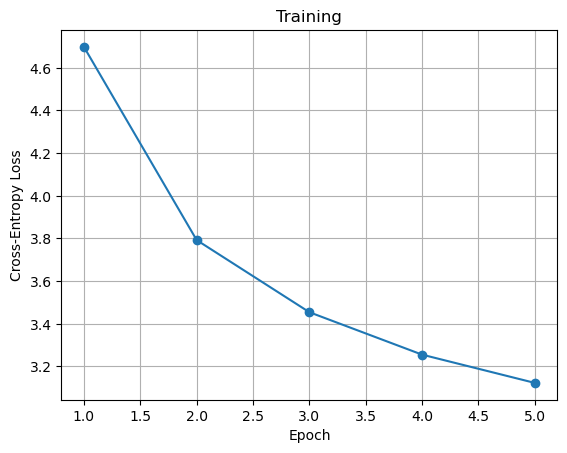

In [ ]:
import matplotlib.pyplot as plt

losses = [4.6980, 3.7925, 3.4544, 3.2555, 3.1230]
epochs = range(1, 6)

plt.plot(epochs, losses, marker='o') 

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Training")
plt.grid(True)  

plt.show()